# Network Design (QOBLIB / 8) - Proposal via QAOA

We propose a numerical solution to QOBLIB problem 8 which presents a graph problem that seeks to optimise traffic flow within a network. This could be applied to a variety of sectors such as telecommunications and traffic management.

## Definition of the Problem

Given an $n × n$ demand matrix $T = (t_{ij})$ (where  $t_{ij}$ represents traffic from node $i$ to node $j$) and an integer $p > 0$:

1. Construct a simple directed graph $D$ with node set $\{1,…,n\}$ where each node has in-degree and out-degree equal to $p$
2. Route $t_{ij}$ defines traffic flow from $i$ to $j$ for all $1 ≤ i,j ≤ n$ with $i ≠ j$
3. Minimize the maximum aggregate flow on any edge of $D$

Instance Parameters:
+ $p = 2$ (each node has 2 incoming and 2 outgoing connections)
+ $n∈\{5,…,24\}$ nodes
+ Demand matrix entries: $t_{ij} ∈{0}∪[16,100]$

## Preliminaries

The following cells precede the algorithm used to find the optimal traffic flow of the network.

In [27]:
import qoblib_tools as qt
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path

import itertools
import time
import warnings

import hybrid
import numpy as np
import requests
from dwave.samplers import SimulatedAnnealingSampler
from IPython.display import display

from divi.backends import JobConfig, MaestroSimulator, QoroService
from divi.backends.characterization import CharacterizationOptions, characterize_and_validate
from divi.qprog.algorithms import PCE, QAOA, PolyEncoding, SoftObjective
from divi.qprog.ensembles import BeamSearchStrategy, PartitioningProgramEnsemble
from divi.qprog.optimizers import MonteCarloOptimizer
from divi.qprog.problems import (
    BinaryOptimizationProblem,
    CommunityDecomposer,
    LinearConstraint,
    QUBOPartitioningConfig,
)

import hybrid
from divi.backends import JobConfig, MaestroSimulator, QoroService
from divi.qprog.ensembles import BeamSearchStrategy, PartitioningProgramEnsemble
from divi.qprog.optimizers import MonteCarloOptimizer
from divi.qprog.problems import BinaryOptimizationProblem, CommunityDecomposer, QUBOPartitioningConfig
import math
from random import Random
from tempfile import TemporaryDirectory

### Helper Functions

In [28]:
def sample_layouts(qubo, backend, cluster_size, layers, seed, *,
                   population_size=8, iterations=3, beam_width=24, partition_candidates=8):
    problem = BinaryOptimizationProblem(
        qubo,
        decomposer=CommunityDecomposer(QUBOPartitioningConfig(max_n_variables_per_cluster=cluster_size)),
        composer=hybrid.SplatComposer(),
    )
    ensemble = PartitioningProgramEnsemble(
        problem=problem,
        quantum_routine="qaoa",
        n_layers=layers,
        optimizer=MonteCarloOptimizer(population_size=population_size),
        max_iterations=iterations,
        backend=backend,
        reporting_level="off",
        seed=seed,
    )
    ensemble.run()
    return ensemble.get_top_solutions(
        n=beam_width, strategy=BeamSearchStrategy(beam_width=beam_width, n_partition_candidates=partition_candidates)
    )


def evaluate_layouts(candidates, qubo, arcs, demand):
    n_nodes = len(demand)
    layout_scores = {}
    best_raw, best_arcs, best_bits = set(), [], ""
    best_score = math.inf
    for bits, _ in candidates:
        sample = dict(zip(qubo.variables, bits, strict=True))
        raw_arcs = qt.decode_topology(sample, arcs)
        if qt.is_valid_topology(n_nodes, raw_arcs):
            topology = raw_arcs
        else:
            topology = qt.repair_topology(n_nodes, raw_arcs, demand)

        layout = tuple(sorted(topology))
        if layout in layout_scores:
            continue
        score = qt.route_min_congestion(demand, layout).objective
        layout_scores[layout] = score
        if score < best_score:
            best_score = score
            best_raw = set(raw_arcs)
            best_arcs = sorted(topology)
            best_bits = "".join(str(int(sample[v])) for v in range(len(arcs)))
    return layout_scores, best_score, best_raw, best_arcs, best_bits


def refine_layout(layout, start_score, rng, demand, swaps_per_start):
    edges = set(layout)
    score = start_score
    tried = accepted = 0
    while tried < swaps_per_start:
        first, second = rng.sample(sorted(edges), 2)
        (a, b), (c, d) = first, second
        replacements = {(a, d), (c, b)}
        if a == d or c == b or replacements & edges:
            continue

        trial = (edges - {first, second}) | replacements
        trial_score = qt.route_min_congestion(demand, trial).objective
        tried += 1
        if trial_score < score:
            edges, score = trial, trial_score
            accepted += 1
    return sorted(edges), accepted


def refine_starts(layout_scores, demand, n_starts, swaps_per_start, seed):
    n_nodes = len(demand)
    instance = f"network{n_nodes:02d}"
    starts = sorted((score, layout) for layout, score in layout_scores.items() if math.isfinite(score))
    best_checked_score, best_routing = math.inf, None
    print("Start   Initial LP   Accepted   Checked score")
    with TemporaryDirectory() as scratch:
        trial_file = Path(scratch) / f"{instance}.sol"
        for rank, (start_score, layout) in enumerate(starts[:n_starts], start=1):
            refined, accepted = refine_layout(layout, start_score, Random(seed + rank - 1), demand, swaps_per_start)
            candidate_routing = qt.route_integral(demand, refined)
            qt.write_network_solution(trial_file, n_nodes, candidate_routing)
            valid, score, message = qt.check_network_solution(trial_file, n_nodes, demand)
            if not valid:
                raise ValueError(f"Start {rank} failed the solution checker: {message}")
            print(f"{rank:>5}   {start_score:>10,.0f}   {accepted:>8}   {score:>13,}")
            if score < best_checked_score:
                best_checked_score, best_routing = score, candidate_routing
    return best_checked_score, best_routing

In [30]:
def solve_partitioned(bqm, routine="qaoa", cluster_size=12, n_layers=2, backend=backend, decomposer=None, **routine_kwargs):
    # Partition `bqm`, solve every part with `routine`, and return the ensemble.
    # routine: "qaoa" | "iterative_qaoa" | "pce" | "progressive_pce"
    problem = BinaryOptimizationProblem(
        bqm,
        decomposer=decomposer or CommunityDecomposer(
            QUBOPartitioningConfig(max_n_variables_per_cluster=cluster_size)
        ),
        composer=hybrid.SplatComposer(),
        local_search=True,
    )
    ensemble = PartitioningProgramEnsemble(
        problem=problem,
        quantum_routine=routine,
        n_layers=n_layers,
        optimizer=MonteCarloOptimizer(population_size=MC_POPULATION),
        max_iterations=MC_ITERATIONS,
        backend=backend,
        **routine_kwargs,
    )
    ensemble.run()
    return ensemble

### Qoro Quantum Backend Configuration

In [29]:
USE_CLOUD = True            # False: local Maestro simulator · True: Qoro cloud (uses credits)
RUN_CHARACTERIZATION = True  # Characterization Service calls (cloud; cost scales with QUBO size)
SHOTS = 10_000
MC_POPULATION = 50          # Monte Carlo optimiser: circuits per iteration, sent to the backend as one batch
MC_ITERATIONS = 10          # Monte Carlo optimiser iterations

service = QoroService()

def make_backend(shots: int = SHOTS, force_sampling: bool = False):
    # force_sampling=True: estimate everything from shots instead of exact expectation values
    if USE_CLOUD:
        return QoroService(
            job_config=JobConfig(
                shots=shots, simulator_cluster="qoro_maestro", force_sampling=force_sampling
            )
        )
    return MaestroSimulator(shots=shots, force_sampling=force_sampling)


backend = make_backend()
print("Circuits run on:", type(backend).__name__)

Circuits run on: QoroService


### Demand Matrix

A demand matrix is supplied by QOBLIB which contains the desired traffic flow between routers 1 through 24. Each matrix entry gives the traffic from its row router to its column router.

In [31]:
n_nodes = 5
if not 5 <= n_nodes <= 24:
    raise ValueError("Choose an instance between 5 and 24 routers.")

instance = f"network{n_nodes:02d}"
demand = qt.load_network_demand(n_nodes)
print(f"{instance}: {n_nodes} routers")

network05: 5 routers


{(0, 1): Text(0.6976434712938058, 0.5303746147380171, '24'),
 (0, 2): Text(0.12214669620224328, 0.43747891998479815, '43'),
 (0, 3): Text(0.0688273203041807, -0.1503092854164716, '23'),
 (0, 4): Text(0.6113709388229784, -0.4206855407726273, '21')}

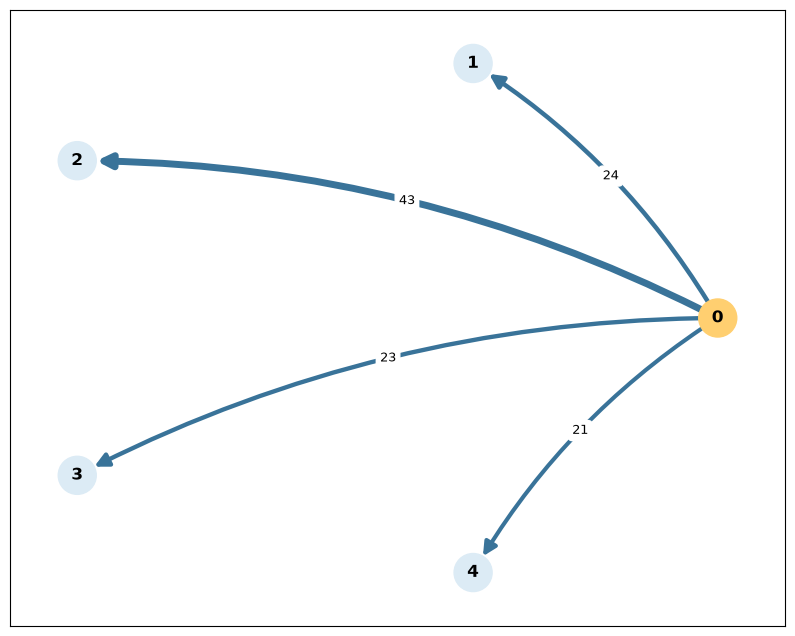

In [32]:
source = 0
min_demand = 1

graph = nx.DiGraph()
graph.add_nodes_from(range(len(demand)))

for i, row in enumerate(demand):
    if source is not None and i != source:
        continue
    for j, amount in enumerate(row):
        if i != j and amount > 0 and amount >= min_demand:
            graph.add_edge(i, j, weight=int(amount))

pos = nx.circular_layout(graph)
fig, ax = plt.subplots(figsize=(10, 8))

weights = nx.get_edge_attributes(graph, "weight")
max_weight = max(weights.values(), default=1)
curve = "arc3,rad=0.12"

nx.draw_networkx_nodes(
    graph, pos, ax=ax, node_size=750,
    node_color=["#ffcf70" if node == source else "#dcebf5" for node in graph],
)
nx.draw_networkx_labels(graph, pos, ax=ax, font_weight="bold")
nx.draw_networkx_edges(
    graph, pos, ax=ax, edgelist=list(weights),
    width=[1 + 4 * w / max_weight for w in weights.values()],
    edge_color="#397399", arrowsize=20, node_size=750, connectionstyle=curve,
)
nx.draw_networkx_edge_labels(
    graph, pos, ax=ax, edge_labels=weights, connectionstyle=curve,
    node_size=750, font_size=9, rotate=False,
)

## Algorithm

## 2. Build the topology QUBO

Each bit selects a possible directed link. The degree penalty favours exactly two links in each direction. The current demand weight of zero gives a degree-only baseline. Set it to 1 to favour direct links for busy pairs.

In [33]:
direct_demand_weight = 0.0
degree_weight = 2.0
direct_demand, degree_penalty, arcs = qt.build_network_qubo(demand)
qubo = direct_demand_weight * direct_demand + degree_weight * degree_penalty
print(f"{len(arcs)} possible directed links; a valid layout uses {2 * n_nodes}.")

20 possible directed links; a valid layout uses 10.


## 3. Ask Divi for candidate networks

Partitioned QAOA samples up to 24 layouts. The local simulator is the default. Cloud execution uses your Qoro API key and credits.

In [34]:
use_cloud = True
shots = 2_000
cluster_size = 8

if use_cloud:
    backend = QoroService(job_config=JobConfig(shots=shots, simulator_cluster="qoro_maestro"))
else:
    backend = MaestroSimulator(shots=shots)

candidates = sample_layouts(qubo, backend, cluster_size, layers=1, seed=7)
print(f"{type(backend).__name__} returned {len(candidates)} candidate layouts.")

QoroService returned 24 candidate layouts.


## 4. Repair and score the layouts

Decode the bits, repair degree violations, and route all demand through each distinct layout. Lower peak link load gives a better score.

In [35]:
layout_scores, best_score, *_ = evaluate_layouts(candidates, qubo, arcs, demand)
if not math.isfinite(best_score):
    raise RuntimeError("No routable candidate. Increase the beam width and rerun from step 3.")
print(f"Distinct layouts: {len(layout_scores)}. Best pre-swap score: {best_score:,.0f}")

Distinct layouts: 11. Best pre-swap score: 76,667


## 5. Refine the best starts and save the solution

Try 200 degree-preserving swaps per start. Compute integer flows, check each finalist, and save the lowest-scoring one in the multistart results folder. Rerunning replaces this instance’s multistart file.

In [36]:
n_starts = 5
swaps_per_start = 200
checked_score, routing = refine_starts(layout_scores, demand, n_starts, swaps_per_start, seed=7)
result_path = Path("starter_results/multistart") / f"{instance}.sol"
result_path.parent.mkdir(parents=True, exist_ok=True)
qt.write_network_solution(result_path, n_nodes, routing)
valid, saved_score, message = qt.check_network_solution(result_path, n_nodes, demand)
if not valid or saved_score != checked_score:
    raise ValueError(f"Solution check failed: {message}, score {saved_score}")
print(f"{result_path} — checked score {saved_score:,}")

Start   Initial LP   Accepted   Checked score
    1       76,667          1          74,667
    2       83,000          3          68,000
    3       83,000          4          68,000
    4       83,000          3          65,500
    5       83,000          2          68,000
starter_results/multistart/network05.sol — checked score 65,500


## 6. Draw the best saved network

Compare checked files for this instance, including earlier runs. Arrows show traffic direction, edge labels show routed load, and orange marks the busiest links.